<a href="https://colab.research.google.com/github/Goat-Seller/bankruptcy-prediction/blob/main/lab7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Data preparation

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme()

data = pd.read_csv('/content/data.csv')

## Data split

In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OrdinalEncoder
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

target = 'Bankrupt?'

x = data.drop(columns=[target])
y = data[target]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1, stratify=y)



chosen_features = [
    'Persistent EPS in the Last Four Seasons',
    'Total debt/Total net worth',
    'Non-industry income and expenditure/revenue',
    'Net Value Growth Rate',
    'Quick Ratio',
    'Tax rate (A)',
    'Cash/Total Assets',
    'Operating Gross Margin',
]


## Task 7.1 - cross validation

In [3]:
import numpy as np

x_train.columns = x_train.columns.str.strip()
x_test.columns = x_test.columns.str.strip()

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

scaler = StandardScaler()

x_train_s_chosen = scaler.fit_transform(x_train[chosen_features])
x_test_s_chosen = scaler.transform(x_test[chosen_features])

clf = LogisticRegression(max_iter=1000, class_weight="balanced")


# Logistic Regression
print("---Logistic Regression---")
acc_scores = cross_val_score(clf, x_train_s_chosen, y_train, cv=5, scoring="accuracy")
print("classification accuracy: ", np.round(acc_scores, 3), "\nmean: ", round(acc_scores.mean(), 3))
print('\n\n')


# SVM
from sklearn import svm
print("---SVM---")
for kernel in ["linear", "poly", "rbf", "sigmoid"]:
    clf = svm.SVC(kernel=kernel, class_weight="balanced")
    acc_scores = cross_val_score(clf, x_train_s_chosen, y_train, cv=5, scoring="accuracy")
    print("classification accuracy: |", kernel,"|" , np.round(acc_scores, 3), "\nmean: ", round(acc_scores.mean(), 3))
    print("\n")
print('\n\n')


---Logistic Regression---
classification accuracy:  [0.826 0.813 0.819 0.816 0.841] 
mean:  0.823



---SVM---
classification accuracy: | linear | [0.822 0.81  0.808 0.797 0.837] 
mean:  0.815


classification accuracy: | poly | [0.867 0.85  0.862 0.851 0.882] 
mean:  0.862


classification accuracy: | rbf | [0.823 0.809 0.819 0.792 0.841] 
mean:  0.817


classification accuracy: | sigmoid | [0.788 0.759 0.786 0.775 0.796] 
mean:  0.781







## Task 7.2

In [8]:
# k-fold cross-validation

# Logistic Regressor

clf = LogisticRegression(max_iter=1000, class_weight="balanced")

for k in [3, 5, 10]:
    acc_scores = cross_val_score(clf, x_train_s_chosen, y_train, cv=k, scoring="accuracy")
    print(k, "fold cross-validation")
    print("classification: ", np.round(acc_scores, 3), "\nmean: ", round(acc_scores.mean(), 3))
    print("\n")

3 fold cross-validation
classification:  [0.821 0.814 0.836] 
mean:  0.823


5 fold cross-validation
classification:  [0.826 0.813 0.819 0.816 0.841] 
mean:  0.823


10 fold cross-validation
classification:  [0.826 0.819 0.795 0.826 0.844 0.809 0.806 0.842 0.839 0.829] 
mean:  0.823




## Task 7.3

In [5]:
from sklearn.model_selection import cross_validate

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "SVM rbf": svm.SVC(kernel="rbf", class_weight="balanced"),
}

for name, clf in models.items():
    res = cross_validate(clf, x_train_s_chosen, y_train, cv=5, scoring=["recall", "precision", "f1"])
    print(name)
    print("recall:   ", np.round(res["test_recall"], 3), "\nmean: ", round(res["test_recall"].mean(), 3))
    print("precision:", np.round(res["test_precision"], 3), "\nmean: ", round(res["test_precision"].mean(), 3))
    print("f1:       ", np.round(res["test_f1"], 3), "\nmean: ", round(res["test_f1"].mean(), 3))
    print("\n")

Logistic Regression
recall:    [0.743 0.857 0.8   0.886 0.806] 
mean:  0.818
precision: [0.126 0.131 0.128 0.136 0.149] 
mean:  0.134
f1:        [0.215 0.227 0.22  0.236 0.251] 
mean:  0.23


SVM rbf
recall:    [0.714 0.886 0.8   0.914 0.806] 
mean:  0.824
precision: [0.12  0.132 0.128 0.125 0.149] 
mean:  0.131
f1:        [0.206 0.23  0.221 0.22  0.251] 
mean:  0.226




## Task 7.4

# Logistic Regression

In [6]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
import pandas as pd

clf = LogisticRegression(max_iter=1000)

parameters = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100],
    "class_weight": [None, "balanced"],
}

grid_search = GridSearchCV(clf, parameters, cv=5, scoring="f1", n_jobs=-1)
grid_search.fit(x_train_s_chosen, y_train)

print(grid_search.best_params_)
print(round(grid_search.best_score_, 3))

cv_res = pd.DataFrame(grid_search.cv_results_)
display(cv_res[["param_C", "param_class_weight", "mean_test_score", "rank_test_score"]]
        .sort_values("rank_test_score").round(3))

{'C': 10, 'class_weight': 'balanced'}
0.23


,param_C,param_class_weight,mean_test_score,rank_test_score
11,100.000,balanced,0.230,1
9,10.000,balanced,0.230,1
7,1.000,balanced,0.230,3
5,0.100,balanced,0.228,4
3,0.010,balanced,0.219,5
1,0.001,balanced,0.206,6
6,1.000,None,0.181,7
8,10.000,None,0.181,7
10,100.000,None,0.181,7
4,0.100,None,0.145,10


## Task 7.5

In [7]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

best_lr = grid_search.best_estimator_      # whole train set
print(grid_search.best_params_)

pred = best_lr.predict(x_test_s_chosen)

print("accuracy: ", round(accuracy_score(y_test, pred), 3))
print("recall:   ", round(recall_score(y_test, pred), 3))
print("precision:", round(precision_score(y_test, pred), 3))
print("f1:       ", round(f1_score(y_test, pred), 3))


{'C': 10, 'class_weight': 'balanced'}
accuracy:  0.834
recall:    0.75
precision: 0.133
f1:        0.226


## 7.4 and 7.5 for SVM

In [8]:
## 7.4
from sklearn.model_selection import GridSearchCV
from sklearn import svm
import pandas as pd

clf = svm.SVC(class_weight="balanced")

parameters = [
    {"kernel": ["linear"], "C": [0.1, 1, 10]},  # linear ignores gamma
    {"kernel": ["rbf", "sigmoid"], "C": [0.1, 1, 10], "gamma": [0.0001, 0.001, 0.01, 0.1]},
]

grid_search = GridSearchCV(clf, parameters, cv=5, scoring="f1", n_jobs=-1)
## f1 takes under consideration precision and recall
grid_search.fit(x_train_s_chosen, y_train)

print(grid_search.best_params_)
print(round(grid_search.best_score_, 3))

cv_res = pd.DataFrame(grid_search.cv_results_)
display(cv_res[["param_kernel", "param_C", "param_gamma", "mean_test_score", "rank_test_score"]]
        .sort_values("rank_test_score").round(3).head(10))

## 7.5

from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

best_svm = grid_search.best_estimator_      # whole train set
print(grid_search.best_params_)

pred = best_svm.predict(x_test_s_chosen)

print("accuracy: ", round(accuracy_score(y_test, pred), 3))
print("recall:   ", round(recall_score(y_test, pred), 3))
print("precision:", round(precision_score(y_test, pred), 3))
print("f1:       ", round(f1_score(y_test, pred), 3))


{'C': 10, 'kernel': 'linear'}
0.224


,param_kernel,param_C,param_gamma,mean_test_score,rank_test_score
2,linear,10.0,NaN,0.224,1
23,rbf,10.0,0.010,0.224,2
1,linear,1.0,NaN,0.223,3
0,linear,0.1,NaN,0.222,4
17,rbf,1.0,0.100,0.222,5
25,rbf,10.0,0.100,0.220,6
15,rbf,1.0,0.010,0.219,7
21,rbf,10.0,0.001,0.217,8
24,sigmoid,10.0,0.010,0.216,9
9,rbf,0.1,0.100,0.216,10


{'C': 10, 'kernel': 'linear'}
accuracy:  0.827
recall:    0.75
precision: 0.128
f1:        0.219


## Task 7.6 for Logistic Regressor

TP: 33 | TN: 1105 | FP: 215 | FN: 11
TPR: 0.75 | TNR: 0.837 | FPR: 0.163 | FNR: 0.25




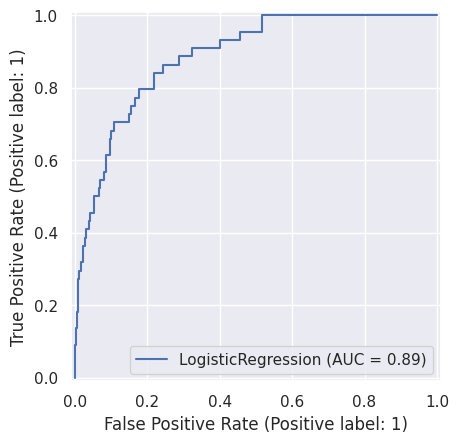

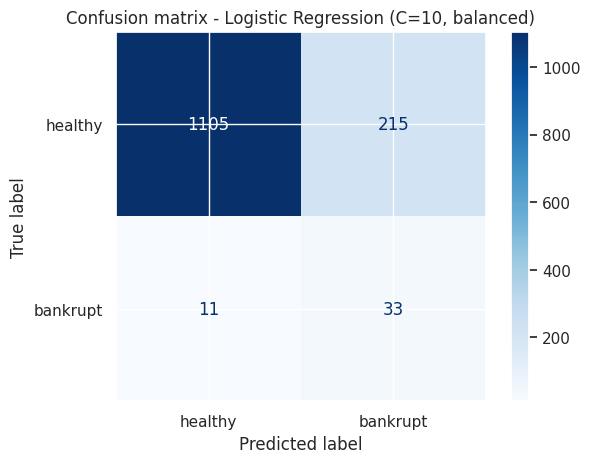

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
import matplotlib.pyplot as plt

lr = LogisticRegression(max_iter=1000, C=10, class_weight="balanced")
lr.fit(x_train_s_chosen, y_train)
pred = lr.predict(x_test_s_chosen)


## TPR, TNR, FPR, FNR
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

print("TP:", tp, "| TN:", tn, "| FP:", fp, "| FN:", fn)

print("TPR:", round(tp / (tp + fn), 3),
      "| TNR:", round(tn / (tn + fp), 3),
      "| FPR:", round(fp / (fp + tn), 3),
      "| FNR:", round(fn / (fn + tp), 3))

print("\n")
## ROC
RocCurveDisplay.from_estimator(lr, x_test_s_chosen, y_test)
plt.show()

print("\n")

## confusion matrix
pred = lr.predict(x_test_s_chosen)

cm = confusion_matrix(y_test, pred)
cm_display = ConfusionMatrixDisplay(cm, display_labels=["healthy", "bankrupt"]).plot(cmap=plt.cm.Blues)
plt.title("Confusion matrix - Logistic Regression (C=10, balanced)")
plt.show()

## Task 7.6 for SVM

TP: 33 | TN: 1105 | FP: 215 | FN: 11
TPR: 0.75 | TNR: 0.837 | FPR: 0.163 | FNR: 0.25




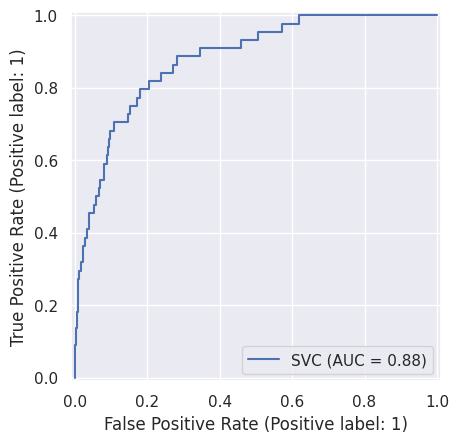

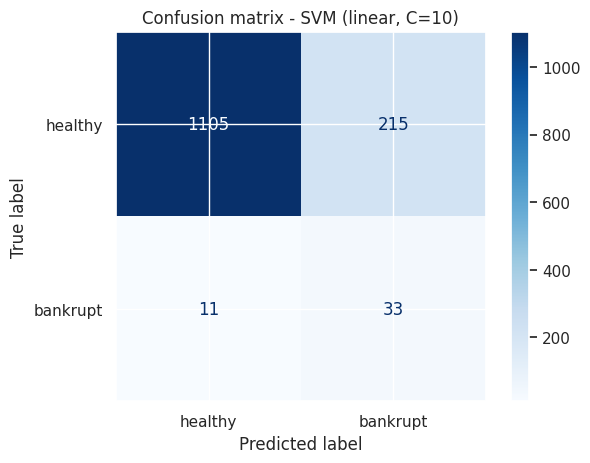

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
import matplotlib.pyplot as plt


best_svm = svm.SVC(kernel="linear", C=10, class_weight="balanced")
best_svm.fit(x_train_s_chosen, y_train)

## TPR, TNR, FPR, FNR
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

print("TP:", tp, "| TN:", tn, "| FP:", fp, "| FN:", fn)

print("TPR:", round(tp / (tp + fn), 3),
      "| TNR:", round(tn / (tn + fp), 3),
      "| FPR:", round(fp / (fp + tn), 3),
      "| FNR:", round(fn / (fn + tp), 3))

print("\n")

## ROC
RocCurveDisplay.from_estimator(best_svm, x_test_s_chosen, y_test)
plt.show()

print("\n")
## confusion matrix
cm = confusion_matrix(y_test, pred)
cm_display = ConfusionMatrixDisplay(cm, display_labels=["healthy", "bankrupt"]).plot(cmap=plt.cm.Blues)
plt.title("Confusion matrix - SVM (linear, C=10)")
plt.show()